# 3 · Survival: when should a forager leave a patch?

Survival mode has no guns. Creatures walk a hilly world, eat food and pay energy
every tick. Here we test a classic idea from ecology, Charnov's **Marginal Value
Theorem** (1976): a forager should leave a food patch when what it gains there
drops below what it could get elsewhere.

**Question:** at how much remaining food should a creature stop eating and move on?

Background: [survival guide, level 2](../docs/survival-guide.md#level-2-when-to-leave-a-patch).

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from terrabots.framework.actions import Action, MoveDirection
from terrabots.framework.agent import Agent
from terrabots.framework.observation import Observation
from terrabots.framework.simulation import ResourceConfig, SimConfig, Simulation
from terrabots.map_generator import procedural

## The rules that matter

Every tick costs 1 energy (2 when walking). Standing on food gives
`min(20, food left) − 2` per tick. So eating pays as long as more than about
2–3 units are left, but staying also means not walking to richer food.

The forager below eats until the food under it drops to `LEAVE_AT`, then walks
to the best food in sight (amount per distance).

In [2]:
class Forager(Agent):
    """Eats until the cell drops to LEAVE_AT, then heads for the best food in sight."""

    LEAVE_AT = 3.0

    def decide(self, obs: Observation) -> Action:
        here = next((r for r in obs.visible_resources if r.pos == obs.pos), None)
        if here is not None and here.amount > self.LEAVE_AT:
            return Action(move_direction=MoveDirection.STAY)
        others = [r for r in obs.visible_resources if r.pos != obs.pos]
        if others:
            best = max(others, key=lambda r: r.amount / (1 + abs(r.pos[0] - obs.pos[0]) + abs(r.pos[1] - obs.pos[1])))
            return Action(move_toward=best.pos)
        return Action(move_direction=MoveDirection.RANDOM)

def leaving_at(v):
    return type(f"Forager_{v:g}", (Forager,), {"LEAVE_AT": v})

## One world

A world is a 48 × 48 procedural map. We make food scarcer than the default
(half as many new food cells per tick); otherwise most creatures live to the
end whatever they do and there's nothing to compare. `run()` returns one
snapshot per tick; we count how many ticks each creature was alive (at most 500).

In [3]:
SCARCE = SimConfig(resource=ResourceConfig(spawn_rate=0.15))   # half the usual new food

def lifetimes(cls, seed, creatures=6, ticks=500, config=SCARCE):
    random.seed(seed)                                   # world, food and start cells
    sim = Simulation(procedural(48, 48, rng=random), config)
    sim.add_agent(cls, count=creatures)
    snaps = sim.run(ticks=ticks)
    alive = {}
    for snap in snaps:
        for a in snap.agents:
            alive[a["id"]] = alive.get(a["id"], 0) + a["alive"]
    return list(alive.values())

print(lifetimes(Forager, seed=1))

[155, 140, 267, 104, 188, 500]


## The experiment

Six thresholds, six worlds each, the same eight worlds for every threshold.
Each world holds six creatures of one kind, so they compete only with their
own kind.

In [4]:
THRESHOLDS = [0, 5, 10, 20, 30, 45]
rows = []
for v in THRESHOLDS:
    for seed in range(6):
        for life in lifetimes(leaving_at(v), seed):
            rows.append({"leave_at": v, "seed": seed, "lifetime": life})

df = pd.DataFrame(rows)
per_world = df.groupby(["leave_at", "seed"])["lifetime"].mean().reset_index()
summary = per_world.groupby("leave_at")["lifetime"].agg(["mean", "std", "size"])
summary["ci95"] = 2.571 * summary["std"] / np.sqrt(summary["size"])   # t, 5 degrees of freedom
summary.round(1)

,mean,std,size,ci95
leave_at,,,,
0,358.5,75.5,6,79.2
5,380.1,106.8,6,112.1
10,414.9,50.2,6,52.7
20,446.7,46.9,6,49.2
30,451.9,37.8,6,39.7
45,462.7,48.9,6,51.4


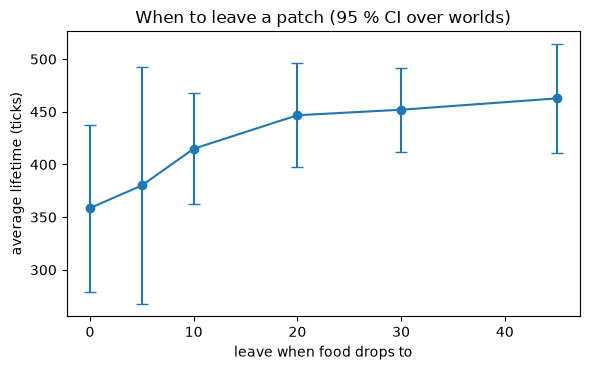

In [5]:
plt.figure(figsize=(6, 3.8))
plt.errorbar(summary.index, summary["mean"], yerr=summary["ci95"], fmt="o-", capsize=4)
plt.xlabel("leave when food drops to"); plt.ylabel("average lifetime (ticks)")
plt.title("When to leave a patch (95 % CI over worlds)")
plt.tight_layout()

## Reading the result

The curve keeps rising: in this world, **leaving early wins**. Charnov's theorem
explains why. What counts is the intake rate here compared with the rate you
could get elsewhere, travel included:

- Eating gives the full 18 per tick only while at least 20 food is left. Below
  that the rate drops fast: a cell with 10 left gives just 8.
- A creature sees 15 cells far, so there is usually a rich cell in sight, worth
  18 per tick after a short walk. A good "elsewhere" means leaving early.
- Food left behind regrows (0.5 per tick), so it isn't wasted.

From 20 upwards the intervals overlap, so the data can't separate those
thresholds. Note that we averaged per **world** before computing the interval:
the six creatures in one world share the same luck, so they aren't independent
samples.

## Exercises

1. **Test the theorem's prediction.** When the next patch is far away, staying
   should pay more. Make food much sparser (`spawn_rate=0.05`, and
   `initial_density=0.02`). Does the best threshold drop?
2. **Charnov's rule.** Instead of a fixed threshold, estimate your average
   intake over the last 50 ticks and leave when the current cell gives less.
3. **Competition.** Put two kinds in the same world (`sim.add_agent` twice). Does
   the best threshold change when rivals eat the same food?
4. **Terrain.** Climbing costs energy. Replace the amount-per-distance rule with
   one that also counts the height difference. Measure it the same way.

The survival guide continues with search strategies, communication, learning
and evolution.